# Classification Track — Part B
## 08. AdaBoost Classifier

**Notes from the algorithm list:** Tune n_estimators and learning_rate.

AdaBoost builds a sequence of weak learners (shallow trees by default), re-weighting the training samples so that each new learner concentrates on the examples the previous ones got wrong. The final prediction is a weighted vote. Unlike Random Forest, the trees are trained **sequentially**, so `n_estimators` and `learning_rate` interact.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              confusion_matrix, classification_report, roc_auc_score,
                              roc_curve, auc)
from sklearn.preprocessing import label_binarize
import os, time

RANDOM_STATE = 42
sns.set_style("whitegrid")

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")
class_map = pd.read_csv("../data/processed/class_mapping.csv", index_col=0)["class_name"].to_dict()
class_names = [class_map[i] for i in sorted(class_map.keys())]

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Classes:", class_names)

X_train: (1688, 21)  X_test: (423, 21)
Classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


### Model training: baseline (default parameters) vs. tuned (GridSearchCV)

A default-parameter **baseline** is trained first so the improvement from tuning can be documented (Review 2 rubric A3). Both models use the same train split, and both are scored on the same held-out test set.

In [2]:
ALGO_KEY = "adaboost"
ALGO_DISPLAY = "AdaBoost"

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Default AdaBoost uses depth-1 stumps; they are too weak for a 7-class problem, so the tuning grid also
# varies the depth of the weak learner.
baseline = AdaBoostClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_acc = accuracy_score(y_test, base_pred)
base_f1 = f1_score(y_test, base_pred, average='weighted')
print(f"Baseline (default params) -> Accuracy: {base_acc:.4f} | Weighted F1: {base_f1:.4f}")

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0],
    'estimator': [DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
                  DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)]
}
grid = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), param_grid,
                    cv=5, scoring='f1_weighted', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV weighted-F1:", round(grid.best_score_, 4))
ada = grid.best_estimator_

Baseline (default params) -> Accuracy: 0.6974 | Weighted F1: 0.6318


Best params: {'estimator': DecisionTreeClassifier(max_depth=3, random_state=42), 'learning_rate': 0.5, 'n_estimators': 100}
Best CV weighted-F1: 0.9804


### Effect of hyperparameters (tuning)

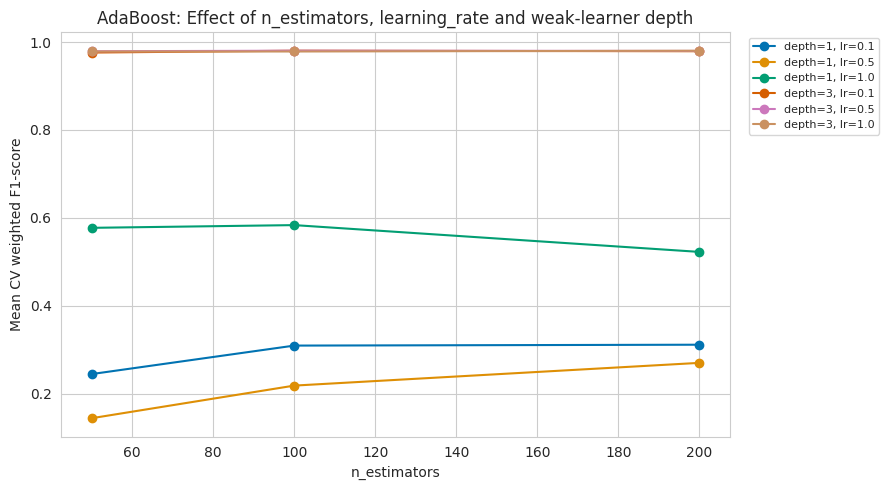

In [3]:
results_df = pd.DataFrame(grid.cv_results_)
results_df['weak_learner_depth'] = results_df['param_estimator'].apply(lambda e: e.max_depth)
pivot = results_df.pivot_table(index='param_n_estimators', columns=['weak_learner_depth', 'param_learning_rate'],
                               values='mean_test_score')

plt.figure(figsize=(9, 5))
palette = sns.color_palette("colorblind", n_colors=pivot.shape[1])
for col, colr in zip(pivot.columns, palette):
    plt.plot(pivot.index.astype(int), pivot[col], marker='o', color=colr,
             label=f"depth={col[0]}, lr={col[1]}")
plt.xlabel("n_estimators")
plt.ylabel("Mean CV weighted F1-score")
plt.title("AdaBoost: Effect of n_estimators, learning_rate and weak-learner depth")
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("../results/fig_adaboost_tuning.png", bbox_inches="tight")
plt.show()

**Discussion:** `learning_rate` shrinks each learner's contribution — a smaller value needs more estimators to reach the same fit but is less likely to overfit. Depth-1 stumps are the textbook AdaBoost weak learner, but a 7-class problem with interacting features (`Weight`, `Height`, `BMI`) usually benefits from slightly deeper weak learners; the grid compares both.

### Prediction

Use the tuned model to predict on the held-out test set (`X_test`), which the model has never seen during `.fit()`.

In [4]:
y_pred = ada.predict(X_test)
y_proba = ada.predict_proba(X_test)

print("Predictions generated for", len(y_pred), "test samples.")
print("First 10 predicted labels:", [class_map[i] for i in y_pred[:10]])
print("First 10 actual labels   :", [class_map[i] for i in y_test.values[:10]])

Predictions generated for 423 test samples.
First 10 predicted labels: ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Normal_Weight', 'Obesity_Type_I', 'Normal_Weight']
First 10 actual labels   : ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Normal_Weight', 'Obesity_Type_I', 'Overweight_Level_I']


### Evaluation

In [5]:
acc = accuracy_score(y_test, y_pred)
f1_weighted = f1_score(y_test, y_pred, average='weighted')
precision_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average='weighted')

y_test_bin = label_binarize(y_test, classes=sorted(class_map.keys()))
roc_auc_ovr = roc_auc_score(y_test_bin, y_proba, multi_class='ovr', average='weighted')

print(f"Accuracy           : {acc:.4f}")
print(f"Weighted Precision  : {precision_weighted:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Weighted F1-score   : {f1_weighted:.4f}")
print(f"ROC-AUC (OvR, wtd)  : {roc_auc_ovr:.4f}")
print()
print("Full classification report:")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

Accuracy           : 0.9882
Weighted Precision  : 0.9882
Weighted Recall     : 0.9882
Weighted F1-score   : 0.9882
ROC-AUC (OvR, wtd)  : 0.9992

Full classification report:
                     precision    recall  f1-score   support

Insufficient_Weight       1.00      1.00      1.00        54
      Normal_Weight       0.98      0.98      0.98        58
     Obesity_Type_I       0.99      1.00      0.99        70
    Obesity_Type_II       0.98      1.00      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.98      0.97      0.97        58
Overweight_Level_II       0.98      0.98      0.98        58

           accuracy                           0.99       423
          macro avg       0.99      0.99      0.99       423
       weighted avg       0.99      0.99      0.99       423



### Baseline vs. tuned

In [6]:
print(f"{'Model':<22}{'Accuracy':>10}{'Weighted F1':>14}")
print(f"{'Baseline (default)':<22}{base_acc:>10.4f}{base_f1:>14.4f}")
print(f"{'Tuned (GridSearchCV)':<22}{acc:>10.4f}{f1_weighted:>14.4f}")
print(f"{'Change':<22}{acc-base_acc:>+10.4f}{f1_weighted-base_f1:>+14.4f}")

Model                   Accuracy   Weighted F1
Baseline (default)        0.6974        0.6318
Tuned (GridSearchCV)      0.9882        0.9882
Change                   +0.2908       +0.3564


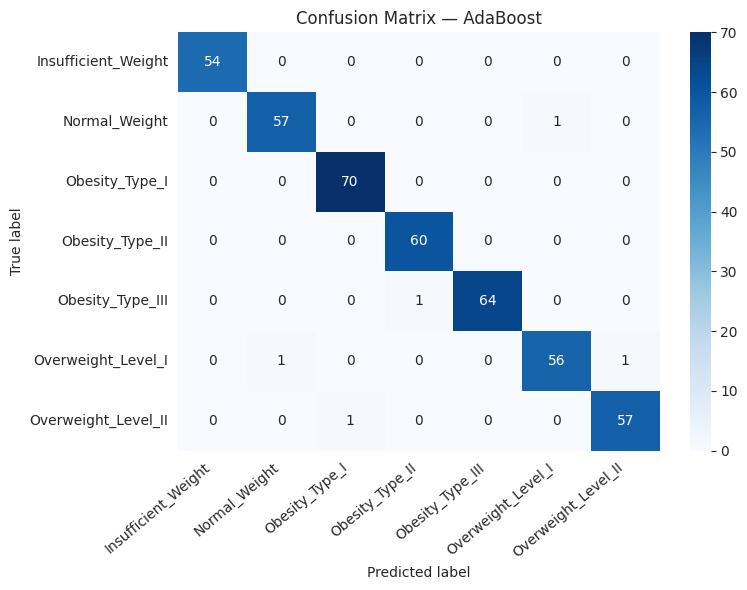

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"Confusion Matrix — {ALGO_DISPLAY}")
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"../results/fig_confusion_matrix_{ALGO_KEY}.png", bbox_inches="tight")
plt.show()

### ROC Curves (One-vs-Rest)

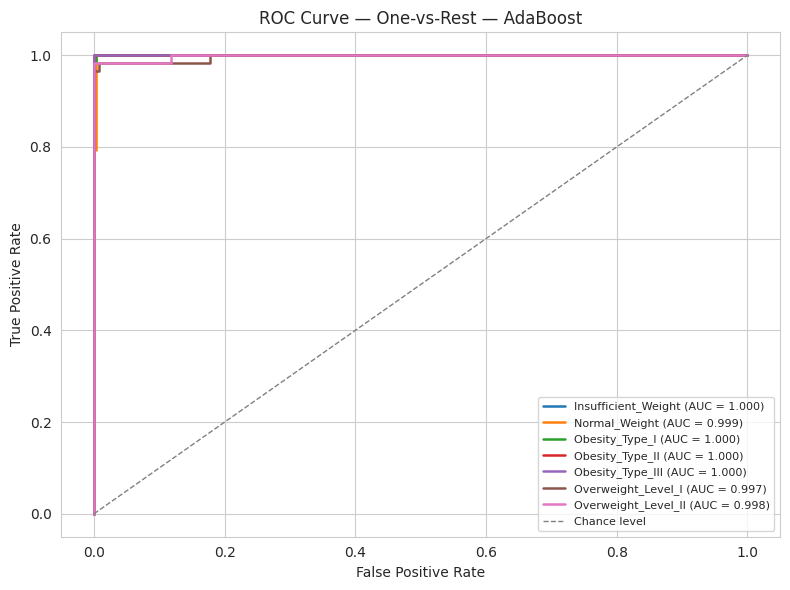

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("tab10", n_colors=len(class_names))

for i, cname in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc_i = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[i], lw=1.8, label=f"{cname} (AUC = {roc_auc_i:.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1, label='Chance level')
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"ROC Curve — One-vs-Rest — {ALGO_DISPLAY}")
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(f"../results/fig_roc_curve_{ALGO_KEY}.png", bbox_inches="tight")
plt.show()

In [9]:
TUNED_MODEL = ada
# Save the tuned model (guidelines: models/ folder, .pkl via joblib) -- reused by notebook 12 for cross-validation
import joblib
os.makedirs("../models", exist_ok=True)
joblib.dump(TUNED_MODEL, f"../models/{ALGO_KEY}.pkl")

# Log baseline-vs-tuned comparison (feeds Review 2 rubric A3: "improvement in at least one metric documented")
tuning_path = "../results/part_b_tuning_log.csv"
trow = pd.DataFrame([{
    "Algorithm": ALGO_DISPLAY,
    "Baseline_F1_weighted": round(base_f1, 4),
    "Tuned_F1_weighted": round(f1_weighted, 4),
    "Baseline_Accuracy": round(base_acc, 4),
    "Tuned_Accuracy": round(acc, 4),
    "Best_CV_F1": round(grid.best_score_, 4),
    "Best_Params": str(grid.best_params_),
}])
if os.path.exists(tuning_path):
    ex = pd.read_csv(tuning_path)
    ex = ex[ex["Algorithm"] != ALGO_DISPLAY]
    trow = pd.concat([ex, trow], ignore_index=True)
trow.to_csv(tuning_path, index=False)

results_path = "../results/part_b_results.csv"
row = pd.DataFrame([{
    "Algorithm": ALGO_DISPLAY,
    "Accuracy": round(acc, 4),
    "Precision_weighted": round(precision_weighted, 4),
    "Recall_weighted": round(recall_weighted, 4),
    "F1_weighted": round(f1_weighted, 4),
    "ROC_AUC_OvR": round(roc_auc_ovr, 4),
}])

if os.path.exists(results_path):
    existing = pd.read_csv(results_path)
    existing = existing[existing["Algorithm"] != ALGO_DISPLAY]
    combined = pd.concat([existing, row], ignore_index=True)
else:
    combined = row

combined.to_csv(results_path, index=False)
print(f"Logged result for '{ALGO_DISPLAY}' to part_b_results.csv:")
row

Logged result for 'AdaBoost' to part_b_results.csv:


,Algorithm,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC_OvR
0,AdaBoost,0.9882,0.9882,0.9882,0.9882,0.9992
